1. Importación de librerías

In [ ]:
import os
import csv
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.applications import DenseNet201
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import Sequence
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    CSVLogger
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# ============================================================
# SEMILLA PARA REPRODUCIBILIDAD
# ============================================================

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

2. Configuración del experimento y directorios

In [ ]:
# ============================================================
# CONFIGURACIÓN GENERAL
# ============================================================

from pathlib import Path

# Modificar esta ruta según la ubicación de los datos
DATA_DIR = Path("./datos_dbt")

# Subcarpetas donde se encuentran los .npy
IMAGENES_DIR = os.path.join(DATA_DIR, "Imagenes")
ETIQUETAS_DIR = os.path.join(DATA_DIR, "Etiquetas")

# Parámetros principales del experimento
BATCH_SIZE = 8
N_UNFROZEN = 200
MAX_EPOCHS = 50
LEARNING_RATE = 1e-5
DROPOUT = 0.30

# Carpeta exclusiva de este experimento
CKPT_DIR = os.path.join(
    DATA_DIR,
    f"checkpoints_DenseNet201_{N_UNFROZEN}capas"
)
os.makedirs(CKPT_DIR, exist_ok=True)

# Archivos de guardado
LAST_MODEL = os.path.join(
    CKPT_DIR,
    "ultimo_checkpoint.keras"
)

BEST_MODEL = os.path.join(
    CKPT_DIR,
    "mejor_modelo.keras"
)

LOG_FILE = os.path.join(
    CKPT_DIR,
    "training_log.csv"
)

FINAL_MODEL = os.path.join(
    CKPT_DIR,
    f"DenseNet201_balanceado_{N_UNFROZEN}capas.keras"
)

print("Carpeta del experimento:")
print(CKPT_DIR)


Carpeta del experimento:
C:\Users\Trons\OneDrive\Escritorio\Tesis\DBT_imagenes_nuevo\checkpoints_DenseNet201_200capas


### Datos de entrada

Este experimento se realizó utilizando archivos NumPy (`.npy`) previamente generados a partir del conjunto BCS-DBT.

Para ejecutar el notebook, los archivos de imágenes deben ubicarse en `datos_dbt/Imagenes/` y los archivos de etiquetas en `datos_dbt/Etiquetas/`, conservando los nombres indicados en el código.

Los resultados mostrados corresponden a la ejecución experimental original. El procedimiento de preprocesamiento documentado en este repositorio permite preparar nuevos conjuntos de datos, pero no garantiza reproducir exactamente las mismas imágenes ni las métricas obtenidas.

3. Carga de datos

In [ ]:
print("=== Cargando datasets ===")

# Imágenes
X_train = np.load(
    os.path.join(IMAGENES_DIR, "X_train_nuevo.npy"),
    mmap_mode="r"
)

X_val = np.load(
    os.path.join(IMAGENES_DIR, "X_val.npy"),
    mmap_mode="r"
)

X_test = np.load(
    os.path.join(IMAGENES_DIR, "X_test_final.npy"),
    mmap_mode="r"
)

# Etiquetas
y_train = np.load(
    os.path.join(ETIQUETAS_DIR, "y_train_nuevo.npy")
)

y_val = np.load(
    os.path.join(ETIQUETAS_DIR, "y_val.npy")
)

y_test = np.load(
    os.path.join(ETIQUETAS_DIR, "y_test_final.npy")
)

print("\nDimensiones:")
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

print("\nDistribución de clases:")
print("Train:", np.bincount(y_train))
print("Val  :", np.bincount(y_val))
print("Test :", np.bincount(y_test))


=== Cargando datasets ===

Dimensiones:
Train: (3197, 512, 512, 1) (3197,)
Val  : (400, 512, 512, 1) (400,)
Test : (400, 512, 512, 1) (400,)

Distribución de clases:
Train: [1600 1597]
Val  : [200 200]
Test : [200 200]


4. Generador de imagenes

In [ ]:
class DBTGenerator(Sequence):

    def __init__(self, X, y, batch_size=8, shuffle=False):
        super().__init__()

        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.shuffle = shuffle

        self.indexes = np.arange(len(X))

        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch_size))

    def __getitem__(self, idx):

        batch_idx = self.indexes[
            idx * self.batch_size:
            (idx + 1) * self.batch_size
        ]

        batch_X = self.X[batch_idx]
        batch_y = self.y[batch_idx]

        X_out = np.zeros(
            (len(batch_X), 512, 512, 3),
            dtype=np.float32
        )

        for i, img in enumerate(batch_X):

            # Si la imagen viene con un canal explícito, se elimina.
            img_2d = img[:, :, 0] if len(img.shape) == 3 else img

            # 1 canal -> 3 canales
            X_out[i] = np.stack(
                [img_2d, img_2d, img_2d],
                axis=-1
            )

        return X_out, batch_y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)


5. Creación de los generadores

In [ ]:
# Si aparece un error de memoria, puede probarse BATCH_SIZE = 4.

train_gen = DBTGenerator(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_gen = DBTGenerator(
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_gen = DBTGenerator(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batches de entrenamiento:", len(train_gen))
print("Batches de validación   :", len(val_gen))
print("Batches de test         :", len(test_gen))


Batches de entrenamiento: 400
Batches de validación   : 50
Batches de test         : 50


6. Creación o recuperación del modelo

In [ ]:
initial_epoch = 0

if os.path.exists(LAST_MODEL):

    print("=== Recuperando checkpoint existente ===")

    model = tf.keras.models.load_model(LAST_MODEL)

    # Si existe el log, se usa para estimar cuántas épocas ya finalizaron.
    if os.path.exists(LOG_FILE):
        with open(LOG_FILE, "r", encoding="utf-8") as f:
            initial_epoch = max(sum(1 for _ in f) - 1, 0)

    print("Épocas ya registradas:", initial_epoch)

else:

    print("=== Creando DenseNet201 nueva ===")

    base_model = DenseNet201(
        weights="imagenet",
        include_top=False,
        pooling="avg",
        input_shape=(512, 512, 3)
    )

    # Congelar todas las capas excepto las últimas N_UNFROZEN.
    for layer in base_model.layers[:-N_UNFROZEN]:
        layer.trainable = False

    for layer in base_model.layers[-N_UNFROZEN:]:
        layer.trainable = True

    total_capas = len(base_model.layers)
    capas_entrenables = sum(layer.trainable for layer in base_model.layers)

    print("Capas totales del backbone :", total_capas)
    print("Capas entrenables backbone :", capas_entrenables)
    print("Capas congeladas backbone  :", total_capas - capas_entrenables)

    # Cabeza clasificadora
    x = layers.Dropout(DROPOUT)(base_model.output)

    output = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = Model(
        inputs=base_model.input,
        outputs=output
    )

    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision")
        ]
    )

print("\nParámetros totales del modelo:", model.count_params())


=== Creando DenseNet201 nueva ===
Capas totales del backbone : 708
Capas entrenables backbone : 200
Capas congeladas backbone  : 508

Parámetros totales del modelo: 18323905


7. Callbacks

In [ ]:
callbacks = [

    # Detiene el entrenamiento si val_loss deja de mejorar.
    EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),

    # Guarda solamente el modelo con menor val_loss.
    ModelCheckpoint(
        BEST_MODEL,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    # Guarda el estado de cada época para poder recuperar
    # un entrenamiento interrumpido.
    ModelCheckpoint(
        LAST_MODEL,
        save_best_only=False,
        verbose=1
    ),

    # Registra las métricas de cada época.
    CSVLogger(
        LOG_FILE,
        append=True
    )
]


8. Entrenamiento

In [ ]:
print("=== Iniciando entrenamiento ===")

if initial_epoch < MAX_EPOCHS:

    history = model.fit(
        train_gen,
        validation_data=val_gen,
        initial_epoch=initial_epoch,
        epochs=MAX_EPOCHS,
        callbacks=callbacks,
        verbose=1
    )

else:
    print(
        f"El log ya contiene {initial_epoch} épocas. "
        f"No se inicia un nuevo entrenamiento porque MAX_EPOCHS={MAX_EPOCHS}."
    )


=== Iniciando entrenamiento ===
Epoch 1/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.5812 - auc: 0.6127 - loss: 0.6758 - precision: 0.5716 - recall: 0.6423
Epoch 1: val_loss improved from None to 0.57306, saving model to C:\Users\Trons\OneDrive\Escritorio\Tesis\DBT_imagenes_nuevo\checkpoints_DenseNet201_200capas\mejor_modelo.keras

Epoch 1: finished saving model to C:\Users\Trons\OneDrive\Escritorio\Tesis\DBT_imagenes_nuevo\checkpoints_DenseNet201_200capas\mejor_modelo.keras

Epoch 1: saving model to C:\Users\Trons\OneDrive\Escritorio\Tesis\DBT_imagenes_nuevo\checkpoints_DenseNet201_200capas\ultimo_checkpoint.keras

Epoch 1: finished saving model to C:\Users\Trons\OneDrive\Escritorio\Tesis\DBT_imagenes_nuevo\checkpoints_DenseNet201_200capas\ultimo_checkpoint.keras
400/400 ━━━━━━━━━━━━━━━━━━━━ 2558s 6s/step - accuracy: 0.6146 - auc: 0.6606 - loss: 0.6508 - precision: 0.6130 - recall: 0.6199 - val_accuracy: 0.7075 - val_auc: 0.7717 - val_loss: 0.5731 - val_precision: 0.7456 -

9. Cargar el mejor modelo y guardarlo con un nombre

In [ ]:
print("=== Cargando el mejor modelo ===")

best_model = tf.keras.models.load_model(BEST_MODEL)

# Guardado con un nombre identificable para este experimento.
best_model.save(FINAL_MODEL)

print("Modelo final guardado en:")
print(FINAL_MODEL)


=== Cargando el mejor modelo ===
Modelo final guardado en:
C:\Users\Trons\OneDrive\Escritorio\Tesis\DBT_imagenes_nuevo\checkpoints_DenseNet201_200capas\DenseNet201_balanceado_200capas.keras


10. Predicciones sobre el conjunto de test

In [ ]:
print("=== Generando predicciones de TEST ===")

y_test_prob = best_model.predict(
    test_gen,
    verbose=1
).flatten()

y_test_pred = (
    y_test_prob > 0.5
).astype(int)

print("Predicciones generadas:", len(y_test_pred))


=== Generando predicciones de TEST ===
50/50 ━━━━━━━━━━━━━━━━━━━━ 201s 4s/step
Predicciones generadas: 400


11. Matriz de confusión y métricas

In [ ]:
cm_test = confusion_matrix(
    y_test,
    y_test_pred
)

print("=== MATRIZ DE CONFUSIÓN - TEST ===")
print(cm_test)

print("\n=== REPORTE DE CLASIFICACIÓN - TEST ===")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "Sin estructuras",
            "Con estructuras"
        ],
        zero_division=0
    )
)

# Extraer TN, FP, FN y TP.
tn, fp, fn, tp = cm_test.ravel()

accuracy_test = (tp + tn) / (tp + tn + fp + fn)
sensibilidad_test = tp / (tp + fn) if (tp + fn) > 0 else np.nan
especificidad_test = tn / (tn + fp) if (tn + fp) > 0 else np.nan
auc_test = roc_auc_score(
    y_test,
    y_test_prob
)

print("=== RESUMEN - TEST ===")
print(f"Accuracy      : {accuracy_test:.4f}")
print(f"Sensibilidad : {sensibilidad_test:.4f}")
print(f"Especificidad: {especificidad_test:.4f}")
print(f"AUC           : {auc_test:.4f}")


=== MATRIZ DE CONFUSIÓN - TEST ===
[[159  41]
 [ 69 131]]

=== REPORTE DE CLASIFICACIÓN - TEST ===
                 precision    recall  f1-score   support

Sin estructuras       0.70      0.80      0.74       200
Con estructuras       0.76      0.66      0.70       200

       accuracy                           0.72       400
      macro avg       0.73      0.73      0.72       400
   weighted avg       0.73      0.72      0.72       400

=== RESUMEN - TEST ===
Accuracy      : 0.7250
Sensibilidad : 0.6550
Especificidad: 0.7950
AUC           : 0.7791


12. Curva ROC

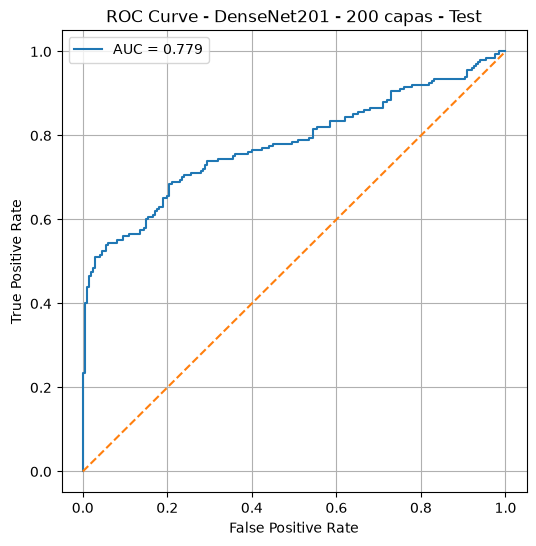

In [ ]:
fpr_test, tpr_test, _ = roc_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(6, 6))

plt.plot(
    fpr_test,
    tpr_test,
    label=f"AUC = {auc_test:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - DenseNet201 - 200 capas - Test")
plt.legend()
plt.grid(True)
plt.show()
